# 01. Sanity Checks & Complexity Analysis (Gomoku 11x11)
**Mục tiêu thực nghiệm:**
1. Kiểm chứng tính đúng đắn của luật Gomoku tiêu chuẩn (5 quân liên tiếp, không xét chặn 2 đầu) và tốc độ thao tác `clone()`.
2. Đo lường mức độ thu hẹp hệ số rẽ nhánh (Branching Factor) khi áp dụng lọc vùng lân cận bán kính $R=2$ so với toàn bàn cờ 121 ô.
3. Kiểm chứng khả năng nhìn ra nước thắng trực tiếp (1-ply tactical check) và tốc độ suy luận trên CPU của `PureMCTSAgent` và `AlphaZeroAgent`.

In [1]:
import sys
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt

# Đảm bảo import được các module từ thư mục gốc dự án
ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from config import CFG, SearchConfig
from environment.caro_env import CaroEnv
from models.resnet import GomokuResNet
from agents.pure_mcts_agent import PureMCTSAgent
from agents.alphazero_agent import AlphaZeroAgent

# Benchmark tốc độ clone() và step() trên CPU
env = CaroEnv()
t0 = time.perf_counter()
for _ in range(10_000):
    c = env.clone()
    c.step(60)
elapsed = time.perf_counter() - t0
print(f"Tốc độ 10,000 vòng clone() + step(): {elapsed:.4f}s ({10_000/elapsed:,.0f} ops/sec)")

Tốc độ 10,000 vòng clone() + step(): 0.0932s (107,308 ops/sec)


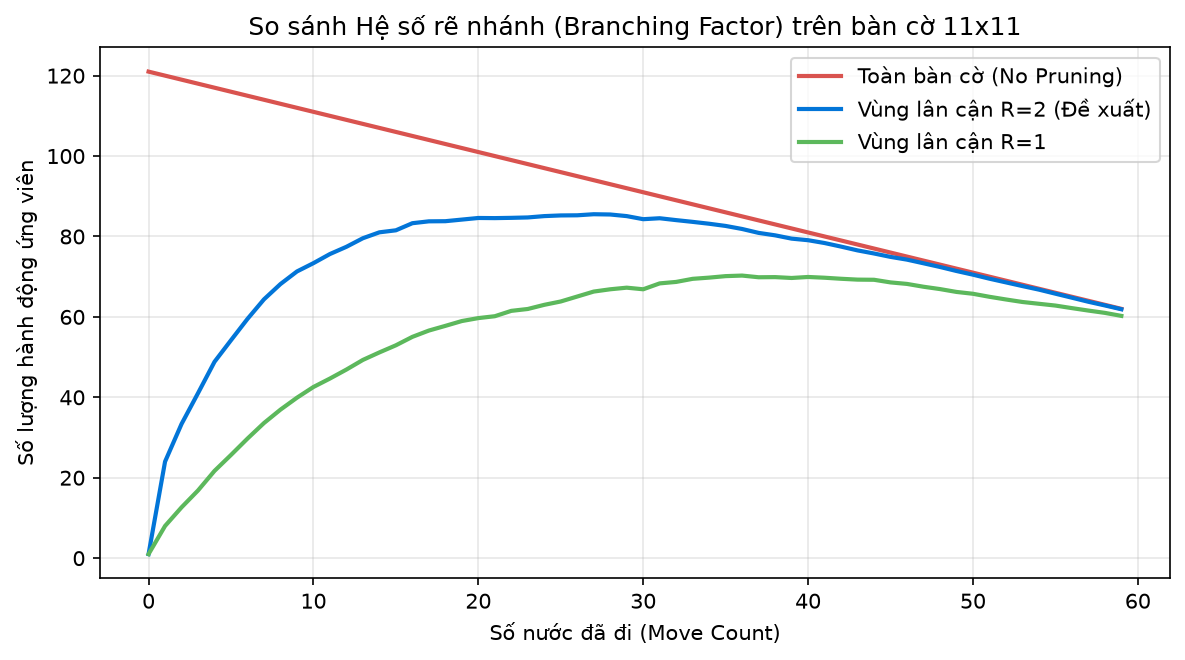

In [2]:
# Mô phỏng 50 ván ngẫu nhiên để đo sự khác biệt giữa toàn bàn cờ vs vùng lân cận R=1, R=2
rng = np.random.default_rng(42)
move_numbers = []
valid_all, valid_r2, valid_r1 = [], [], []

for _ in range(30):
    sim_env = CaroEnv()
    while not sim_env.done and sim_env.move_count < 60:
        move_numbers.append(sim_env.move_count)
        valid_all.append(len(sim_env.get_valid_actions()))
        valid_r2.append(len(sim_env.get_neighbor_actions(radius=2)))
        valid_r1.append(len(sim_env.get_neighbor_actions(radius=1)))
        
        actions = sim_env.get_neighbor_actions(radius=2)
        sim_env.step(int(rng.choice(actions)))

# Vẽ biểu đồ trực quan hóa hệ số rẽ nhánh theo tiến trình ván đấu
plt.figure(figsize=(8, 4.5), dpi=150)
for label, data, color in [
    ("Toàn bàn cờ (No Pruning)", valid_all, "#d9534f"),
    ("Vùng lân cận R=2 (Đề xuất)", valid_r2, "#0275d8"),
    ("Vùng lân cận R=1", valid_r1, "#5cb85c"),
]:
    # Tính trung bình theo từng bước đi
    xs = sorted(set(move_numbers))
    ys = [np.mean([d for m, d in zip(move_numbers, data) if m == x]) for x in xs]
    plt.plot(xs, ys, label=label, linewidth=2, color=color)

plt.title("So sánh Hệ số rẽ nhánh (Branching Factor) trên bàn cờ 11x11")
plt.xlabel("Số nước đã đi (Move Count)")
plt.ylabel("Số lượng hành động ứng viên")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG.paths.log_dir / "branching_factor_comparison.png", dpi=300)
plt.show()

[PASS] Toàn bộ 8 phép biến đổi D4 bảo toàn tính hợp lệ và phân phối xác suất!


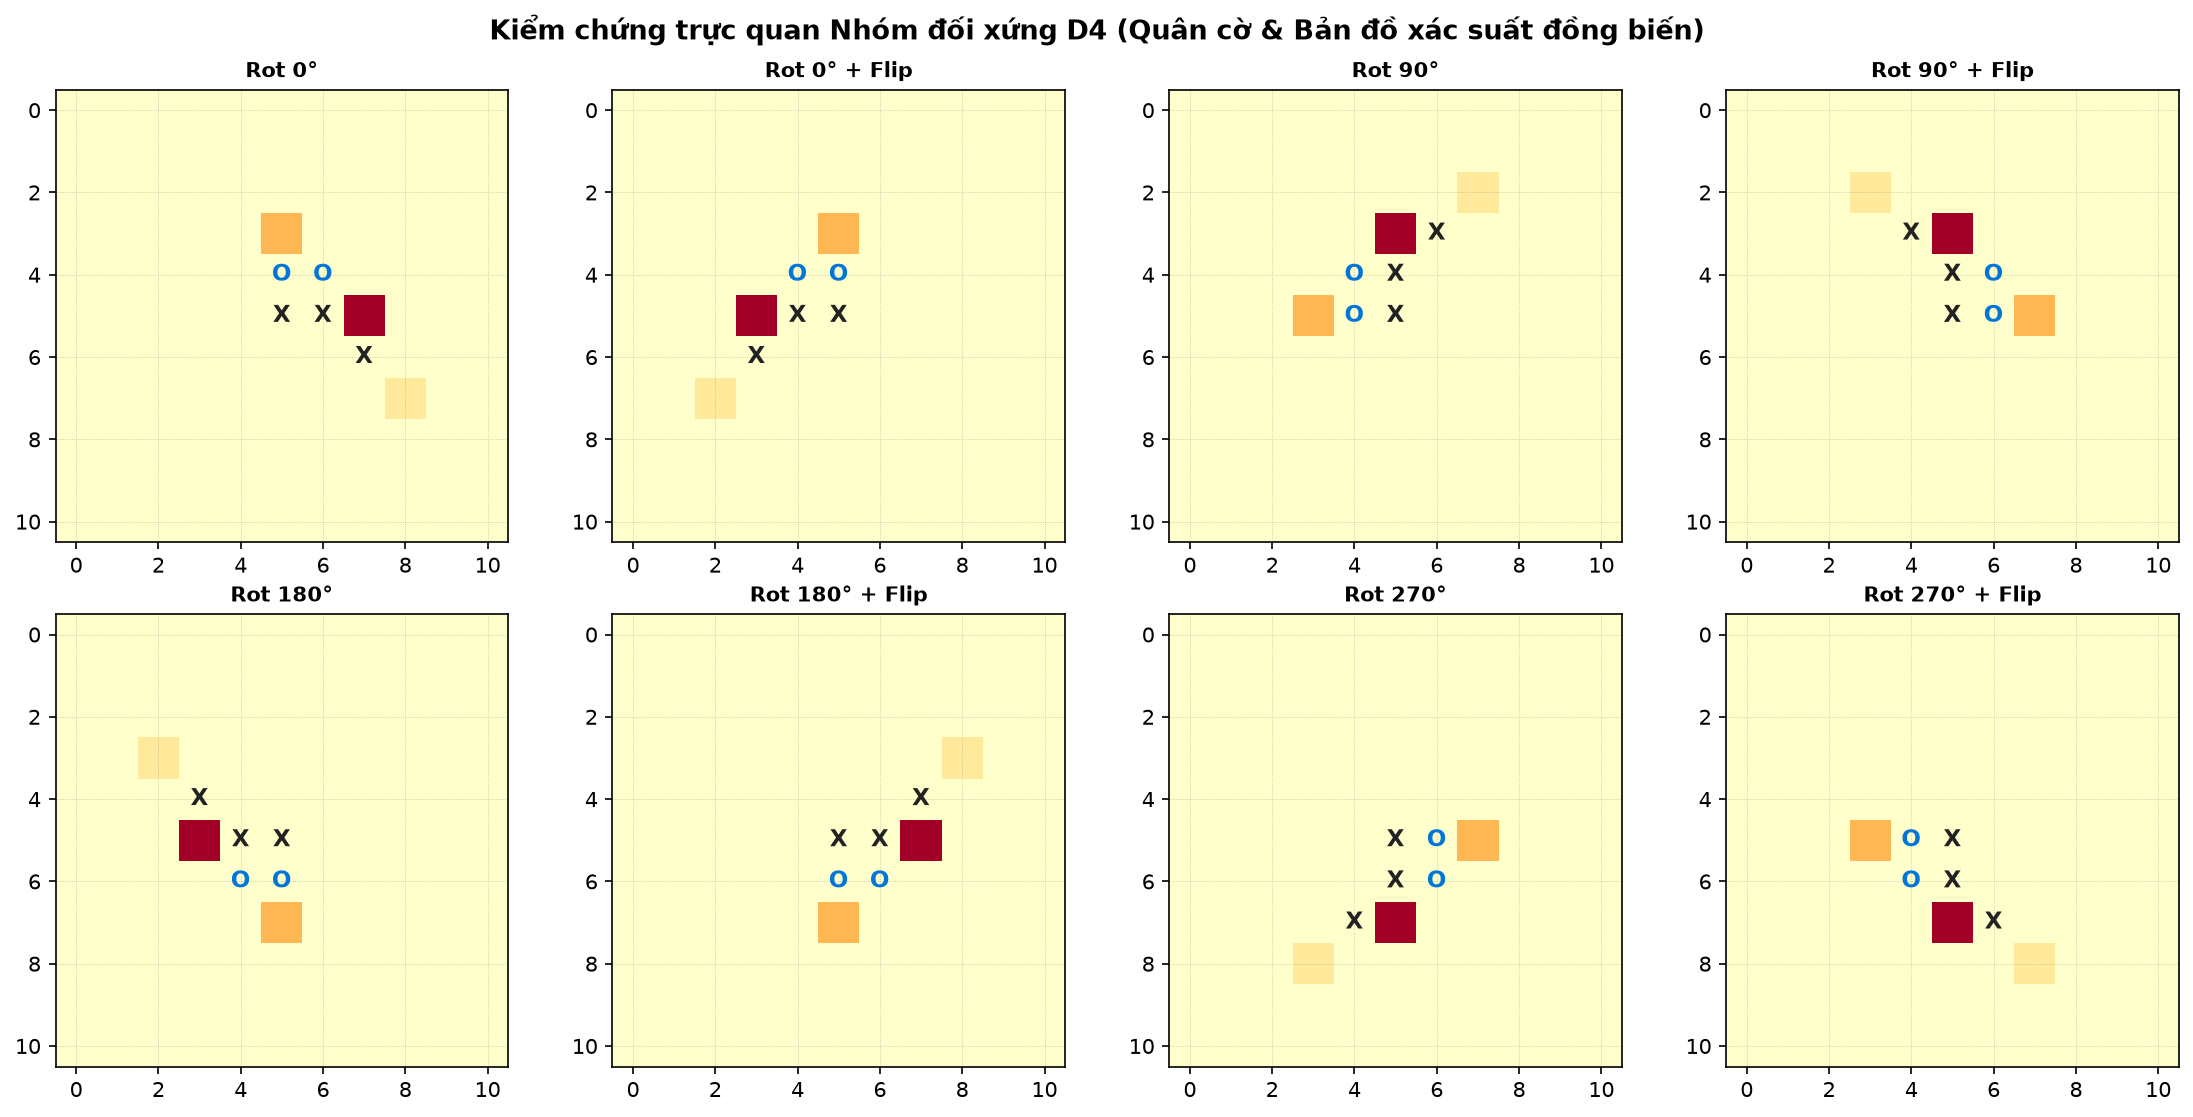

In [3]:
# ==============================================================================
# CELL: KIỂM CHỨNG ĐỐI XỨNG NHỊ DIỆN D4 (8 CHIỀU) CHO DỮ LIỆU SELF-PLAY
# ==============================================================================
def get_d4_symmetries(state: np.ndarray, policy: np.ndarray):
    """
    Tạo 8 cặp (state_transformed, policy_transformed) thuộc nhóm đối xứng hình vuông D4:
    - 4 phép xoay ngược chiều kim đồng hồ: 0, 90, 180, 270 độ.
    - 4 phép lật ngang (fliplr) sau khi xoay.
    """
    board_size = state.shape[1]
    policy_2d = policy.reshape(board_size, board_size)
    symmetries = []

    for k in range(4):
        # Xoay k * 90 độ trên 2 trục không gian (axis 1 và 2 của state)
        rot_state = np.rot90(state, k=k, axes=(1, 2)).copy()
        rot_policy = np.rot90(policy_2d, k=k).copy()
        symmetries.append((f"Rot {k*90}°", rot_state, rot_policy.ravel()))

        # Lật trái-phải sau khi xoay
        flip_state = np.flip(rot_state, axis=2).copy()
        flip_policy = np.fliplr(rot_policy).copy()
        symmetries.append((f"Rot {k*90}° + Flip", flip_state, flip_policy.ravel()))

    return symmetries


# 1. Tạo một thế cờ bất đối xứng mẫu để quan sát rõ sự dịch chuyển tọa độ
env_d4 = CaroEnv()
sample_moves = [(5, 5), (4, 5), (5, 6), (4, 6), (6, 7)]  # Tạo hình chữ L lệch
for r, c in sample_moves:
    env_d4.step(env_d4.coord_to_action(r, c))

state_orig = env_d4.get_canonical_state()
# Giả lập phân phối xác suất tập trung vào các ô chiến thuật quanh (5, 7) và (3, 5)
policy_orig = np.zeros(121, dtype=np.float32)
policy_orig[env_d4.coord_to_action(5, 7)] = 0.65
policy_orig[env_d4.coord_to_action(3, 5)] = 0.25
policy_orig[env_d4.coord_to_action(7, 8)] = 0.10

syms = get_d4_symmetries(state_orig, policy_orig)

# 2. Kiểm tra bất biến toán học: Tổng xác suất = 1 và vị trí quân cờ không đè lên xác suất
for label, s_trans, p_trans in syms:
    assert np.isclose(p_trans.sum(), 1.0), f"Lỗi chuẩn hóa xác suất ở {label}"
    occupied_mask = (s_trans[0] + s_trans[1]).ravel() > 0
    assert np.all(p_trans[occupied_mask] == 0.0), f"Xác suất đè lên ô đã có quân ở {label}"

print("[PASS] Toàn bộ 8 phép biến đổi D4 bảo toàn tính hợp lệ và phân phối xác suất!")

# 3. Trực quan hóa lưới 2x4 kiểm chứng bằng mắt thường
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), dpi=150)
for idx, (label, s_trans, p_trans) in enumerate(syms):
    ax = axes[idx // 4, idx % 4]
    p_grid = p_trans.reshape(11, 11)
    ax.imshow(p_grid, cmap="YlOrRd", vmin=0.0, vmax=0.7)

    # Vẽ quân cờ (Kênh 0: người đi hiện tại - Xanh, Kênh 1: đối thủ - Đen)
    for r in range(11):
        for c in range(11):
            if s_trans[0, r, c] == 1.0:
                ax.text(c, r, "O", ha="center", va="center", color="#0275d8", fontsize=11, fontweight="bold")
            elif s_trans[1, r, c] == 1.0:
                ax.text(c, r, "X", ha="center", va="center", color="#222222", fontsize=11, fontweight="bold")

    ax.set_title(label, fontsize=10, fontweight="bold")
    ax.set_xticks(range(0, 11, 2))
    ax.set_yticks(range(0, 11, 2))
    ax.grid(color="gray", linestyle=":", linewidth=0.4, alpha=0.5)

plt.suptitle("Kiểm chứng trực quan Nhóm đối xứng D4 (Quân cờ & Bản đồ xác suất đồng biến)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(CFG.paths.log_dir / "d4_symmetry_verification.png", dpi=300)
plt.show()

Tổng tham số: 335,266 | Tham số huấn luyện: 335,266
Dung lượng trọng số trên RAM: 1.279 MB

Batch Size =   1 |   2.74 ms/batch | Thông lượng:    365.2 states/sec
Batch Size =   8 |  10.62 ms/batch | Thông lượng:    753.2 states/sec
Batch Size =  32 |  21.70 ms/batch | Thông lượng:   1474.7 states/sec
Batch Size =  64 |  35.51 ms/batch | Thông lượng:   1802.5 states/sec
Batch Size = 128 |  68.32 ms/batch | Thông lượng:   1873.6 states/sec

[Gradient Flow Check - L2 Norm]:
  1. conv_input     : 1.100607
  2. res_block_0    : 3.680001
  3. res_block_last : 1.332979
  4. policy_fc      : 0.331071
  5. value_fc2      : 0.733030


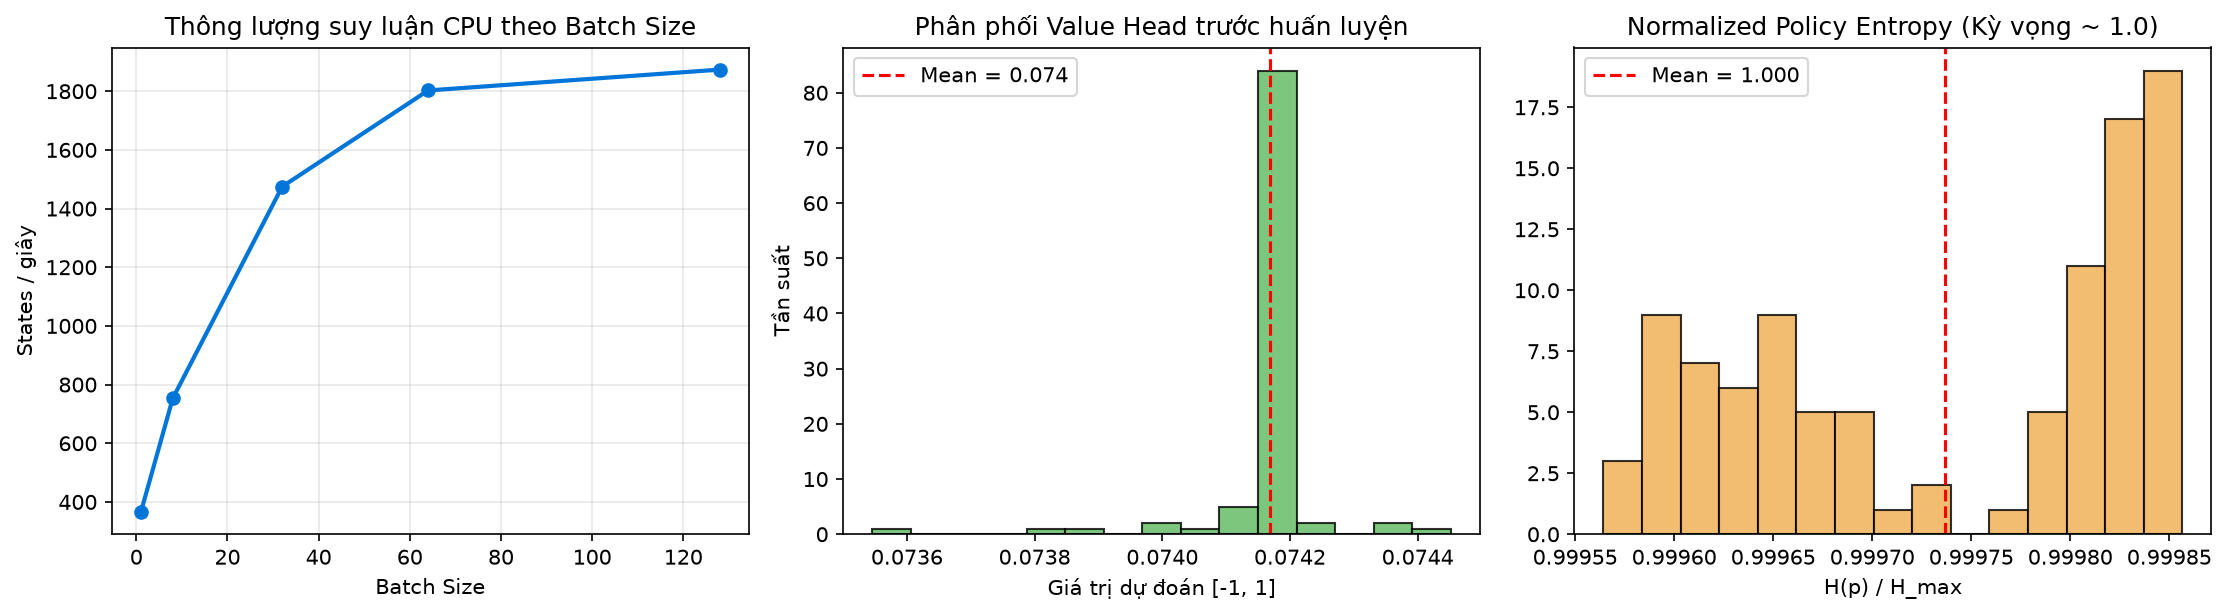

In [4]:
# ==============================================================================
# CELL: GIẢI PHẪU MẠNG RESNET (THAM SỐ, BATCH SPEED, INITIAL BIAS & GRADIENT FLOW)
# ==============================================================================
import torch
import torch.nn as nn

torch.manual_seed(42)
model = GomokuResNet().to("cpu")

# 1. Thống kê số lượng tham số và dung lượng bộ nhớ
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
param_size_mb = sum(p.nelement() * p.element_size() for p in model.parameters()) / (1024 ** 2)

print(f"Tổng tham số: {total_params:,} | Tham số huấn luyện: {trainable_params:,}")
print(f"Dung lượng trọng số trên RAM: {param_size_mb:.3f} MB\n")

# 2. Benchmark tốc độ suy luận theo Batch Size trên CPU (tìm batch tối ưu cho Trainer)
model.eval()
batch_sizes = [1, 8, 32, 64, 128]
throughput_results = []

with torch.no_grad():
    for bs in batch_sizes:
        dummy_input = torch.randn(bs, 3, 11, 11, device="cpu")
        # Warm-up 5 vòng
        for _ in range(5):
            _ = model(dummy_input)

        n_runs = 40
        t0 = time.perf_counter()
        for _ in range(n_runs):
            _ = model(dummy_input)
        elapsed = time.perf_counter() - t0

        ms_per_batch = (elapsed / n_runs) * 1000
        samples_per_sec = (bs * n_runs) / elapsed
        throughput_results.append((bs, ms_per_batch, samples_per_sec))
        print(f"Batch Size = {bs:3d} | {ms_per_batch:6.2f} ms/batch | Thông lượng: {samples_per_sec:8.1f} states/sec")

# 3. Kiểm tra phân phối Value & Entropy khi mới khởi tạo (100 trạng thái ngẫu nhiên)
init_values = []
init_entropies = []
rng_prof = np.random.default_rng(42)

for _ in range(100):
    tmp_env = CaroEnv()
    for _ in range(int(rng_prof.integers(2, 20))):
        if tmp_env.done:
            break
        acts = tmp_env.get_neighbor_actions(radius=2)
        tmp_env.step(int(rng_prof.choice(acts)))

    valid_acts = tmp_env.get_neighbor_actions(radius=2)
    probs, val = model.predict(tmp_env.get_canonical_state(), valid_acts, device="cpu")
    init_values.append(val)

    p_valid = probs[valid_acts]
    p_valid = p_valid[p_valid > 0]
    entropy = -np.sum(p_valid * np.log(p_valid + 1e-12))
    max_entropy = np.log(len(valid_acts))
    init_entropies.append(entropy / max(1e-6, max_entropy))  # Normalized entropy [0, 1]

# 4. Kiểm tra Gradient Flow qua 1 bước lan truyền ngược giả lập
model.train()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
optimizer.zero_grad()

x_batch = torch.randn(16, 3, 11, 11)
target_policy = torch.softmax(torch.randn(16, 121), dim=-1)
target_value = torch.empty(16, 1).uniform_(-1, 1)

pred_logits, pred_value = model(x_batch)
loss_policy = -torch.sum(target_policy * torch.log_softmax(pred_logits, dim=-1), dim=-1).mean()
loss_value = nn.functional.mse_loss(pred_value, target_value)
total_loss = loss_policy + loss_value
total_loss.backward()

grad_norms = {
    "1. conv_input": model.conv_input.weight.grad.norm().item(),
    "2. res_block_0": model.res_blocks[0].conv1.weight.grad.norm().item(),
    "3. res_block_last": model.res_blocks[-1].conv2.weight.grad.norm().item(),
    "4. policy_fc": model.policy_fc.weight.grad.norm().item(),
    "5. value_fc2": model.value_fc2.weight.grad.norm().item(),
}
print("\n[Gradient Flow Check - L2 Norm]:")
for layer_name, g_norm in grad_norms.items():
    print(f"  {layer_name:<18}: {g_norm:.6f}")
    assert g_norm > 1e-7, f"Cảnh báo Vanishing Gradient tại {layer_name}!"

# Vẽ biểu đồ tổng hợp Profiling
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=150)

# Subplot 1: Thông lượng CPU theo Batch Size
axes[0].plot([r[0] for r in throughput_results], [r[2] for r in throughput_results], marker="o", color="#0275d8", linewidth=2)
axes[0].set_title("Thông lượng suy luận CPU theo Batch Size")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("States / giây")
axes[0].grid(alpha=0.3)

# Subplot 2: Phân phối Value khởi tạo
axes[1].hist(init_values, bins=15, color="#5cb85c", edgecolor="black", alpha=0.8)
axes[1].axvline(np.mean(init_values), color="red", linestyle="--", label=f"Mean = {np.mean(init_values):.3f}")
axes[1].set_title("Phân phối Value Head trước huấn luyện")
axes[1].set_xlabel("Giá trị dự đoán [-1, 1]")
axes[1].set_ylabel("Tần suất")
axes[1].legend()

# Subplot 3: Tỷ lệ Entropy chuẩn hóa của Policy Head
axes[2].hist(init_entropies, bins=15, color="#f0ad4e", edgecolor="black", alpha=0.8)
axes[2].axvline(np.mean(init_entropies), color="red", linestyle="--", label=f"Mean = {np.mean(init_entropies):.3f}")
axes[2].set_title("Normalized Policy Entropy (Kỳ vọng ~ 1.0)")
axes[2].set_xlabel("H(p) / H_max")
axes[2].legend()

plt.tight_layout()
plt.savefig(CFG.paths.log_dir / "resnet_profiling_sanity.png", dpi=300)
plt.show()

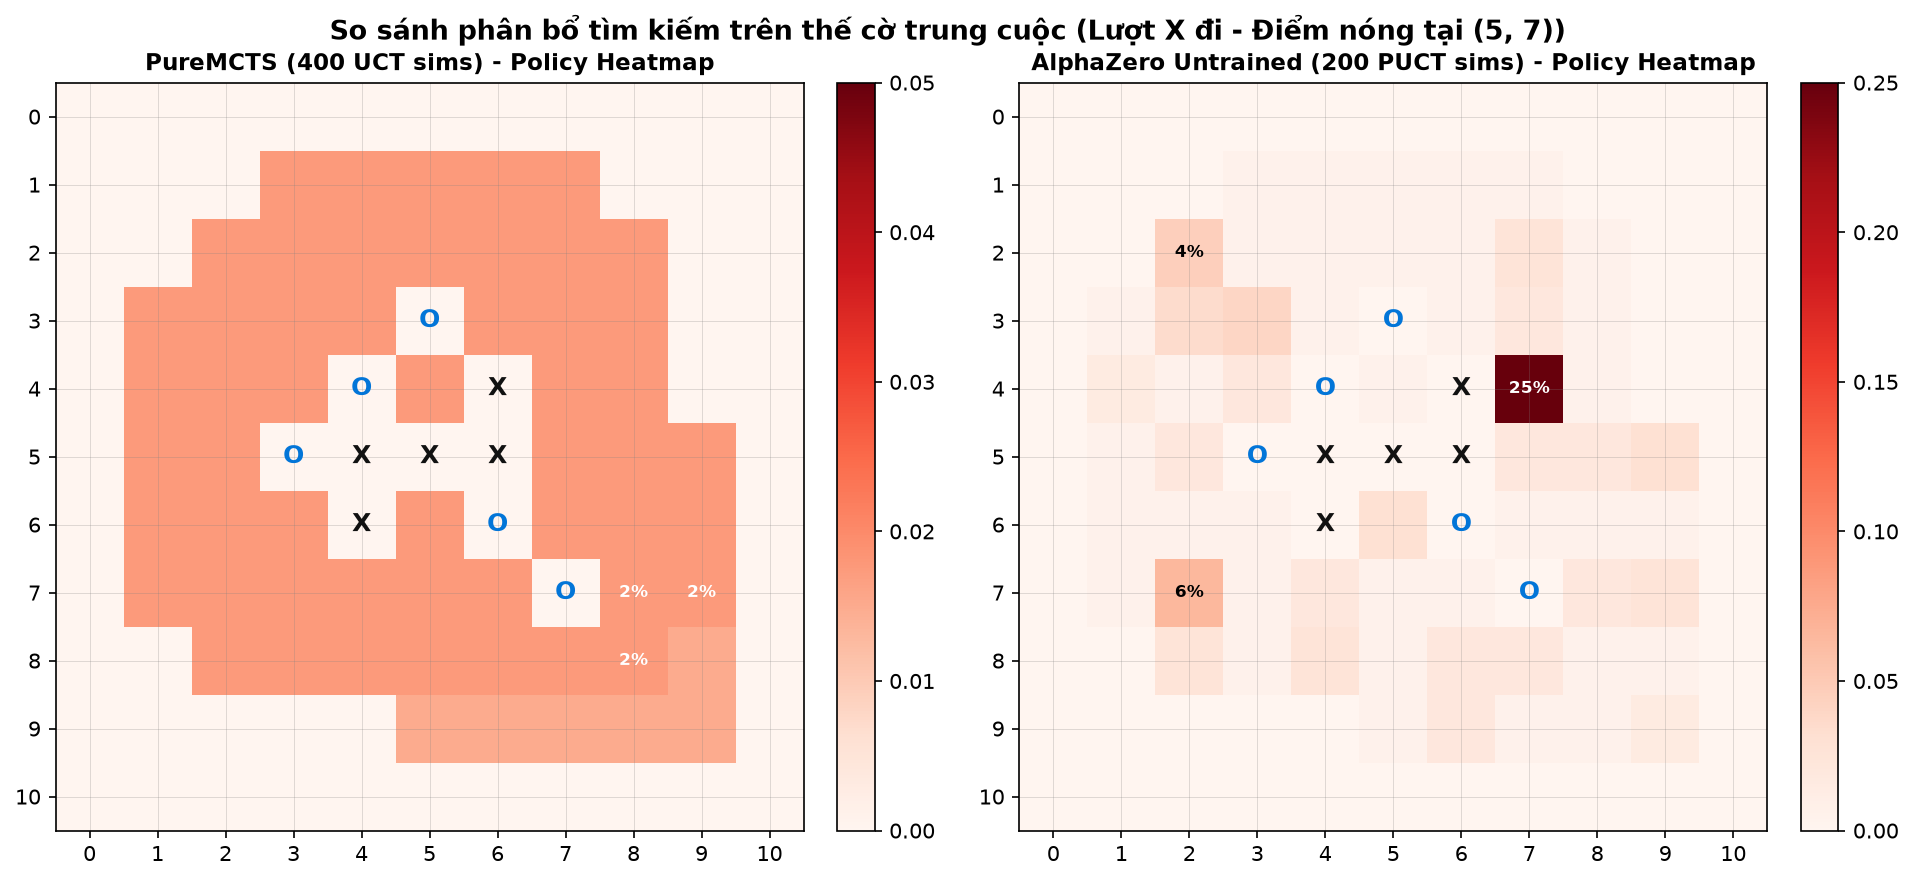

In [5]:
# ==============================================================================
# CELL: TRỰC QUAN HÓA POLICY HEATMAP 11x11 GIỮA PURE MCTS (UCT) VÀ ALPHAZERO (PUCT)
# ==============================================================================
def plot_policy_heatmap(ax, env: CaroEnv, probs: np.ndarray, title: str):
    p_grid = probs.reshape(env.size, env.size)
    im = ax.imshow(p_grid, cmap="Reds", vmin=0.0, vmax=max(0.05, float(p_grid.max())))

    # Tìm Top 3 ô có xác suất cao nhất để gắn nhãn %
    top3_actions = np.argsort(probs)[::-1][:3]
    top3_set = set(top3_actions)

    for r in range(env.size):
        for c in range(env.size):
            cell = env.board[r, c]
            act = env.coord_to_action(r, c)
            if cell == 1:
                ax.text(c, r, "X", ha="center", va="center", color="#111111", fontsize=12, fontweight="bold")
            elif cell == -1:
                ax.text(c, r, "O", ha="center", va="center", color="#0275d8", fontsize=12, fontweight="bold")
            elif act in top3_set and probs[act] > 0:
                ax.text(
                    c, r, f"{probs[act]*100:.0f}%",
                    ha="center", va="center", color="white" if probs[act] > p_grid.max()*0.5 else "black",
                    fontsize=8, fontweight="bold"
                )

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xticks(range(env.size))
    ax.set_yticks(range(env.size))
    ax.grid(color="gray", linestyle="-", linewidth=0.3, alpha=0.4)
    return im


# Dựng một thế cờ trung cuộc kịch tính (10 nước đi):
# X có chuỗi 3 ngang ở hàng 5: (5,4), (5,5), (5,6)
# O có chuỗi 3 chéo: (4,4), (6,6), (7,7) - đang đe dọa nối tại (5,5) nhưng bị X chiếm, O chuyển sang (3,3) & (4,6)
midgame_env = CaroEnv()
opening_seq = [
    (5, 5), (4, 4),
    (5, 6), (6, 6),
    (5, 4), (7, 7),  # X đang có 3 ngang (5,4)-(5,5)-(5,6) thoáng 2 đầu!
    (4, 6), (5, 3),  # O chặn đầu trái (5,3), nhưng đầu phải (5,7) của X vẫn mở!
    (6, 4), (3, 5),
]
for r, c in opening_seq:
    midgame_env.step(midgame_env.coord_to_action(r, c))

# Lấy phân phối xác suất từ cả 2 tác tử
pure_mcts = PureMCTSAgent(search_cfg=SearchConfig(pure_mcts_simulations=400), seed=42)
az_agent = AlphaZeroAgent(search_cfg=SearchConfig(az_simulations=200), device="cpu", seed=42)

probs_mcts = pure_mcts.get_action_probs(midgame_env)
probs_az = az_agent.get_action_probs(midgame_env)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), dpi=150)
im1 = plot_policy_heatmap(axes[0], midgame_env, probs_mcts, "PureMCTS (400 UCT sims) - Policy Heatmap")
im2 = plot_policy_heatmap(axes[1], midgame_env, probs_az, "AlphaZero Untrained (200 PUCT sims) - Policy Heatmap")

fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.suptitle("So sánh phân bổ tìm kiếm trên thế cờ trung cuộc (Lượt X đi - Điểm nóng tại (5, 7))", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(CFG.paths.log_dir / "policy_heatmap_comparison.png", dpi=300)
plt.show()

In [6]:
from agents.alphazero_agent import AlphaZeroAgent
from training.self_play import SelfPlayWorker

az_agent = AlphaZeroAgent()
worker = SelfPlayWorker(agent=az_agent)
samples, stats = worker.generate_batch(num_games=2, verbose=True)
print("Stats:", stats)
print("Sample shapes:", samples[0][0].shape, samples[0][1].shape, samples[0][2])

  [Self-Play] Ván 1/2 | X thắng: 1, O thắng: 0, Hòa: 0 | TB nước đi: 55.0 | Thời gian: 40.6s
  [Self-Play] Ván 2/2 | X thắng: 2, O thắng: 0, Hòa: 0 | TB nước đi: 49.0 | Thời gian: 71.6s
Stats: SelfPlayStats(num_games=2, total_raw_states=98, total_augmented_samples=784, x_wins=2, o_wins=0, draws=0, avg_game_length=49.0, elapsed_sec=71.60341100000369)
Sample shapes: (3, 11, 11) (121,) 1.0
